<a href="https://colab.research.google.com/github/dev-pa5an/windguard-offshore-wind-forecasting/blob/1-create-the-ml-model/Borssele_offshore_wind_farm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Borssele offshore wind farm**

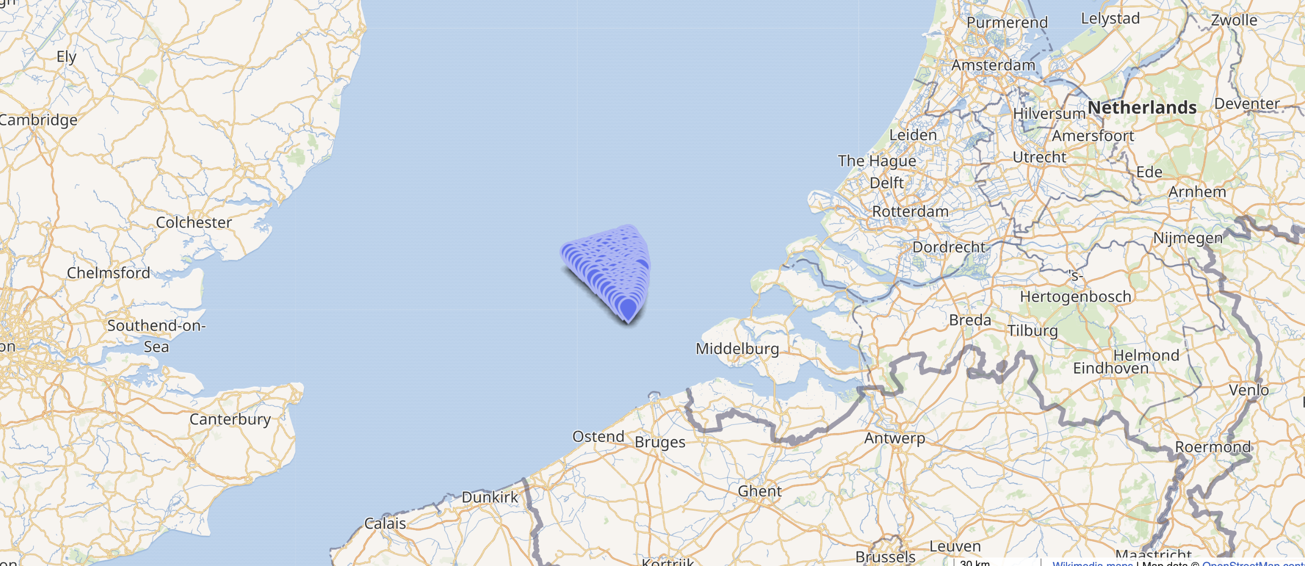

In [ ]:
from PIL import Image

img = Image.open("Borssele_Offshore_Wind_Farm.png")
width, height = img.size
resized_img = img.resize((int(width * 0.5), int(height * 0.5)))
resized_img.save("resized_image.png")
resized_img

In [5]:
!pip install -q ecmwf-datastores-client pyyaml itables xarray netCDF4 h5netcdf xgboost

In [2]:
import yaml
import os
from google.colab import userdata

# Get your API key from Colab Secrets
key = userdata.get('CDS_API_KEY')

# CDS API URL
url = "https://cds.climate.copernicus.eu/api"

# Create credentials dictionary
credentials = {
    "url": url,
    "key": key
}

# Create configuration file in home directory
home_dir = os.path.expanduser("~")
config_path = os.path.join(home_dir, ".ecmwfdatastoresrc")

with open(config_path, "w") as f:
    yaml.safe_dump(credentials, f)

print("Your connection details have been saved!")

Your connection details have been saved!


In [ ]:
from ecmwf.datastores import Client

client = Client()
client.check_authentication()

In [4]:
from ecmwf.datastores import Client

client = Client()

dataset = "reanalysis-era5-single-levels-timeseries"

request = {
    "variable": [
        "100m_u_component_of_wind",
        "100m_v_component_of_wind"
    ],

    "date": [
        "2015-01-01",
        "2024-12-31"
    ],

    # Our selected location
    "location": {
        "longitude": 3.000000,
        "latitude": 51.716667
    },

    "data_format": "netcdf"
}

target = "era5_north_sea_2015_2024.nc"

client.retrieve(
    dataset,
    request,
    target=target
)

print("Download completed!")

e42db52c61f4c2c78c0e778e9711fb48.zip:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Download completed!


In [6]:
import zipfile

zip_path = "/content/era5_north_sea_2015_2024.nc"
extract_dir = "/content/era5_extracted"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Files inside archive:", zip_ref.namelist())
    zip_ref.extractall(extract_dir)

Files inside archive: ['reanalysis-era5-single-levels-timeseries-sfcvcswtqxx.nc']


In [7]:
import os

target = "/content/era5_north_sea_2015_2024.nc"
extract_dir = "/content/era5_extracted"

if zipfile.is_zipfile(target):
    with zipfile.ZipFile(target, "r") as zip_ref:
        print("Files inside ZIP:", zip_ref.namelist())
        zip_ref.extractall(extract_dir)

    nc_files = [
        f for f in os.listdir(extract_dir)
        if f.endswith(".nc")
    ]

    nc_path = os.path.join(extract_dir, nc_files[0])

else:
    nc_path = target

print("NetCDF file:", nc_path)

Files inside ZIP: ['reanalysis-era5-single-levels-timeseries-sfcvcswtqxx.nc']
NetCDF file: /content/era5_extracted/reanalysis-era5-single-levels-timeseries-sfcvcswtqxx.nc


In [9]:
import xarray as xr

ds_all = xr.open_dataset(nc_path, engine="netcdf4")

print(ds_all)

<xarray.Dataset> Size: 1MB
Dimensions:     (valid_time: 87672)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 701kB 2015-01-01 ... 2024-12-31T2...
    latitude    float64 8B ...
    longitude   float64 8B ...
Data variables:
    u100        (valid_time) float32 351kB ...
    v100        (valid_time) float32 351kB ...
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2024-09-02T04:48 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts


In [ ]:
print(ds_all.data_vars)
print(ds_all.dims)

Data variables:
    u100     (valid_time) float32 351kB ...
    v100     (valid_time) float32 351kB ...
FrozenMappingWarningOnValuesAccess({'valid_time': 87672})


In [10]:
import numpy as np
import pandas as pd

wind_speed = np.sqrt(ds_all["u100"]**2 + ds_all["v100"]**2)

df = pd.DataFrame({
    "timestamp": ds_all["valid_time"].values,
    "u100": ds_all["u100"].values,
    "v100": ds_all["v100"].values,
    "wind_speed": wind_speed.values
})

df = df.sort_values("timestamp").reset_index(drop=True)

print(df.head())
print(df.shape)
print(df.isnull().sum())

            timestamp      u100       v100  wind_speed
0 2015-01-01 00:00:00  7.429672   9.978149   12.440398
1 2015-01-01 01:00:00  7.512878   9.832230   12.374008
2 2015-01-01 02:00:00  6.599396  10.690308   12.563229
3 2015-01-01 03:00:00  8.235260   9.381622   12.483363
4 2015-01-01 04:00:00  9.049881   7.074203   11.486718
(87672, 4)
timestamp     0
u100          0
v100          0
wind_speed    0
dtype: int64


In [11]:
print(df["wind_speed"].describe())

count    87672.000000
mean         9.230518
std          4.444281
min          0.021835
25%          5.931622
50%          8.833926
75%         12.122341
max         32.364433
Name: wind_speed, dtype: float64


#Doing 24h list

In [13]:
target_cols = []
for h in range(1, 25):
    col_name = f"target_h{h}"
    df[col_name] = df["wind_speed"].shift(-h)
    target_cols.append(col_name)
df["lag_0"]  = df["wind_speed"]            # hour 23 (latest reading)
df["lag_1"]  = df["wind_speed"].shift(1)   # hour 22
df["lag_3"]  = df["wind_speed"].shift(3)   # hour 20
df["lag_6"]  = df["wind_speed"].shift(6)   # hour 17
df["lag_12"] = df["wind_speed"].shift(12)  # hour 11
df["lag_23"] = df["wind_speed"].shift(23)  # hour 0 (start of today)

df["rolling_mean_24h"] = df["wind_speed"].shift(1).rolling(24).mean()
df["rolling_std_24h"]  = df["wind_speed"].shift(1).rolling(24).std()

df["hour"] = df["timestamp"].dt.hour
df["day_of_year"] = df["timestamp"].dt.dayofyear
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["day_sin"]  = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_cos"]  = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

feature_cols = [
    "lag_0", "lag_1", "lag_3", "lag_6", "lag_12", "lag_23",
    "rolling_mean_24h", "rolling_std_24h",
    "hour_sin", "hour_cos", "day_sin", "day_cos"
]
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor

# 1. Load your ERA5 dataset (as done in the Colab notebook)
# Assuming `df` contains 'timestamp' and 'wind_speed'
df = df.sort_values("timestamp").reset_index(drop=True)

# 2. Create 24 Target Columns (t+1 to t+24 for next day)
target_cols = []
for h in range(1, 25):
    col_name = f"target_h{h}"
    df[col_name] = df["wind_speed"].shift(-h)
    target_cols.append(col_name)

# 3. Construct Input Features from Today's 24 Hourly Actuals
# Lags relative to current time t (end of today's 24 hours)
df["lag_0"]  = df["wind_speed"]            # hour 23 (latest reading)
df["lag_1"]  = df["wind_speed"].shift(1)   # hour 22
df["lag_3"]  = df["wind_speed"].shift(3)   # hour 20
df["lag_6"]  = df["wind_speed"].shift(6)   # hour 17
df["lag_12"] = df["wind_speed"].shift(12)  # hour 11
df["lag_23"] = df["wind_speed"].shift(23)  # hour 0 (start of today)

# Past 24-hour summary statistics
df["rolling_mean_24h"] = df["wind_speed"].shift(1).rolling(24).mean()
df["rolling_std_24h"]  = df["wind_speed"].shift(1).rolling(24).std()

# Cyclical time encoding
df["hour"] = df["timestamp"].dt.hour
df["day_of_year"] = df["timestamp"].dt.dayofyear
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["day_sin"]  = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_cos"]  = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

feature_cols = [
    "lag_0", "lag_1", "lag_3", "lag_6", "lag_12", "lag_23",
    "rolling_mean_24h", "rolling_std_24h",
    "hour_sin", "hour_cos", "day_sin", "day_cos"
]

# Drop NaN values created by lags and target shifts
df_clean = df.dropna().reset_index(drop=True)

# 4. Train-Test Split (e.g., 2015–2022 for training, 2023–2024 for testing)
train = df_clean[df_clean["timestamp"] < "2023-01-01"]
test  = df_clean[df_clean["timestamp"] >= "2023-01-01"]

X_train, y_train = train[feature_cols], train[target_cols]
X_test, y_test   = test[feature_cols], test[target_cols]

# 5. Train Multi-Output XGBoost Model
base_xgb = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
multi_model = MultiOutputRegressor(base_xgb)
multi_model.fit(X_train, y_train)

# 6. Predict Next Day 24-Hour Wind Speed
# Input: Today's feature vector (1, num_features)
# Output: Array of shape (1, 24) containing forecasted wind speeds for hours 1 to 24 of tomorrow
next_day_forecast = multi_model.predict(X_test.iloc[0:1])
print("Predicted 24-hour wind speeds for tomorrow (m/s):")
print(next_day_forecast)

Predicted 24-hour wind speeds for tomorrow (m/s):
[[19.483467  18.651125  18.611734  18.11926   17.898417  18.298223
  17.774902  17.497393  16.622307  16.086386  14.720056  14.9055195
  14.370944  14.128402  14.271367  14.162922  14.467948  14.447625
  14.364884  14.379429  13.978599  14.520305  14.277427  13.2199955]]


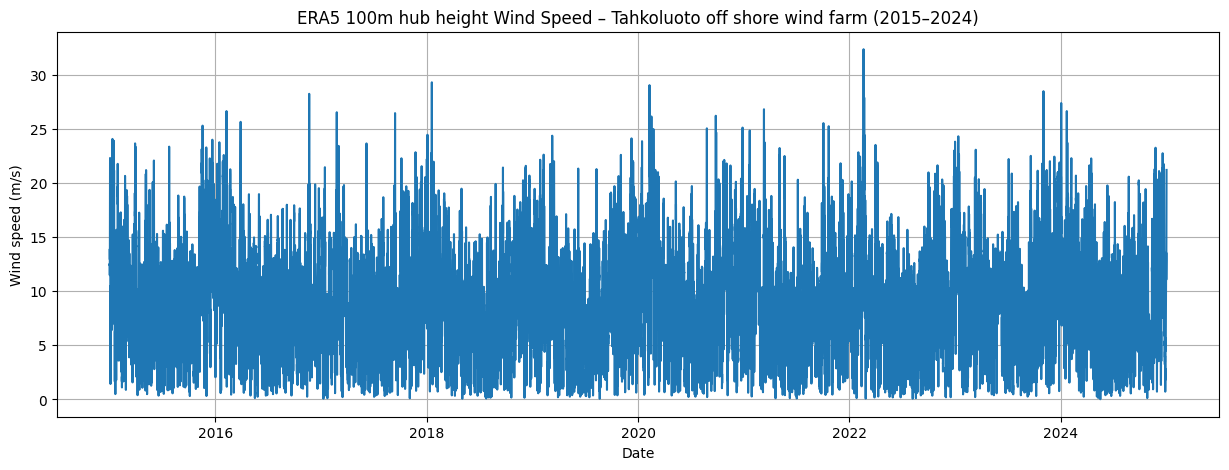

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(df["timestamp"], df["wind_speed"])
plt.xlabel("Date")
plt.ylabel("Wind speed (m/s)")
plt.title("ERA5 100m hub height Wind Speed – Tahkoluoto off shore wind farm (2015–2024)")
plt.grid(True)
plt.show()

In [16]:
# Filter rows where wind speed is 25 m/s or greater
high_wind_df = df[df["wind_speed"] >= 25.0][["timestamp", "wind_speed"]]

# Sort chronologically and reset index
high_wind_df = high_wind_df.sort_values("timestamp").reset_index(drop=True)

# Summary of high-wind events
print(high_wind_df.describe())

                           timestamp  wind_speed
count                             83   83.000000
mean   2020-05-19 21:39:45.542168576   26.435867
min              2015-11-17 21:00:00   25.017380
25%              2018-01-18 07:30:00   25.411564
50%              2020-09-25 16:00:00   26.045685
75%              2022-02-18 16:30:00   26.843066
max              2024-01-22 04:00:00   32.364433
std                              NaN    1.415564



Total hours with wind speed >= 25 m/s: 83
Sample storm cut-out timestamps:
                timestamp  wind_speed
7677  2015-11-17 21:00:00   25.302629
9662  2016-02-08 14:00:00   26.647213
9663  2016-02-08 15:00:00   26.045685
9664  2016-02-08 16:00:00   25.356169
10829 2016-03-28 05:00:00   25.017380


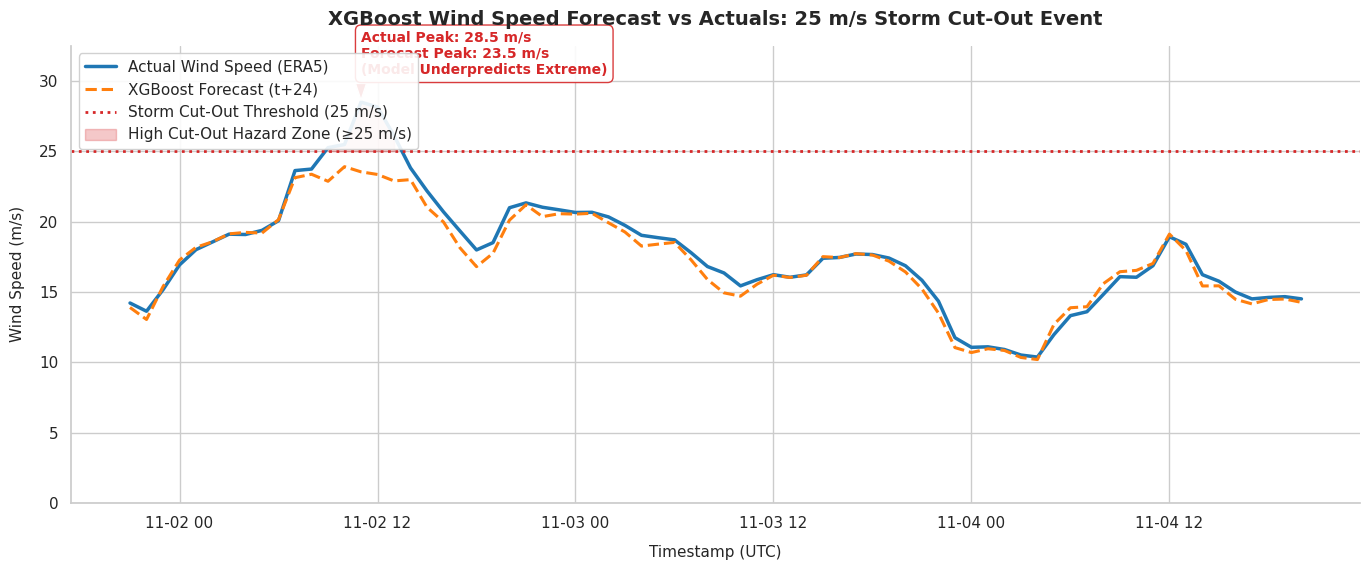

In [18]:
high_wind_events = df_clean[df_clean["wind_speed"] >= 25.0][["timestamp", "wind_speed"]]
print(f"\nTotal hours with wind speed >= 25 m/s: {len(high_wind_events)}")
if len(high_wind_events) > 0:
    print("Sample storm cut-out timestamps:")
    print(high_wind_events.head())

# ==============================================================================
# 4. EVALUATION & VISUALIZATION (72-Hour Window containing Storm Event)
# ==============================================================================
# Predict on test set
y_pred = multi_model.predict(X_test)

# Select a 72-hour window from the test set for evaluation
# (If storm event exists in test set, pick window around it; otherwise first 72 hrs)
storm_test_indices = test[test["wind_speed"] >= 25.0].index
if len(storm_test_indices) > 0:
    start_idx = max(0, test.index.get_loc(storm_test_indices[0]) - 12)
else:
    start_idx = 0

eval_df = test.iloc[start_idx : start_idx + 72].copy()
# Extract single-step lag predictions for continuous visualization
eval_df["predicted_wind_speed"] = y_pred[start_idx : start_idx + 72, 0]

# --- PLOTTING ---
fig, ax = plt.subplots(figsize=(14, 6))

# Plot Actuals vs Forecast
ax.plot(eval_df['timestamp'], eval_df['wind_speed'],
        label='Actual Wind Speed (ERA5)', color='#1f77b4', linewidth=2.5)

ax.plot(eval_df['timestamp'], eval_df['predicted_wind_speed'],
        label='XGBoost Forecast (t+24)', color='#ff7f0e', linewidth=2.2, linestyle='--')

# Storm Cut-Out Threshold (25 m/s)
CUTOUT_THRESHOLD = 25.0
ax.axhline(CUTOUT_THRESHOLD, color='#d62728', linestyle=':', linewidth=2,
           label=f'Storm Cut-Out Threshold ({CUTOUT_THRESHOLD:.0f} m/s)')

# Shade Cut-Out Hazard Region (Actual >= 25 m/s)
is_cutout = eval_df['wind_speed'] >= CUTOUT_THRESHOLD
if is_cutout.any():
    ax.fill_between(
        eval_df['timestamp'],
        y1=eval_df['wind_speed'],
        y2=CUTOUT_THRESHOLD,
        where=is_cutout,
        color='#d62728', alpha=0.25,
        label='High Cut-Out Hazard Zone (≥25 m/s)'
    )

    # Annotate Peak Divergence
    max_idx = eval_df['wind_speed'].idxmax()
    peak_time = eval_df.loc[max_idx, 'timestamp']
    peak_actual = eval_df.loc[max_idx, 'wind_speed']
    peak_pred = eval_df.loc[max_idx, 'predicted_wind_speed']

    ax.annotate(
        f'Actual Peak: {peak_actual:.1f} m/s\nForecast Peak: {peak_pred:.1f} m/s\n(Model Underpredicts Extreme)',
        xy=(peak_time, peak_actual),
        xytext=(peak_time, peak_actual + 2.0),
        arrowprops=dict(facecolor='#d62728', shrink=0.08, width=1.5, headwidth=8),
        fontsize=10, fontweight='bold', color='#d62728',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#d62728', alpha=0.9)
    )

# Formatting
ax.set_title('XGBoost Wind Speed Forecast vs Actuals: 25 m/s Storm Cut-Out Event',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Timestamp (UTC)', fontsize=11, labelpad=10)
ax.set_ylabel('Wind Speed (m/s)', fontsize=11, labelpad=10)

max_val = max(eval_df['wind_speed'].max(), eval_df['predicted_wind_speed'].max())
ax.set_ylim(0, max(32, max_val + 4))

sns.despine(top=True, right=True)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout(pad=1.5)

# Save figure
plt.savefig('storm_cutout_forecast.png', dpi=150, bbox_inches='tight')
plt.show()

#February 18, 2022 Prediction - Eunic storm day


=== 24-Hour Forecast vs Actuals for February 18, 2022 ===
          timestamp  actual_wind_speed_ms  predicted_wind_speed_ms
2022-02-18 00:00:00             11.415592                10.017026
2022-02-18 01:00:00             11.009455                 9.817831
2022-02-18 02:00:00             10.699005                 9.816833
2022-02-18 03:00:00             11.907766                10.239843
2022-02-18 04:00:00             13.923205                11.295538
2022-02-18 05:00:00             16.271988                12.251435
2022-02-18 06:00:00             17.542803                13.649580
2022-02-18 07:00:00             18.292593                14.122764
2022-02-18 08:00:00             20.171469                15.515996
2022-02-18 09:00:00             20.814075                16.652851
2022-02-18 10:00:00             24.513397                18.302822
2022-02-18 11:00:00             23.164606                17.155779
2022-02-18 12:00:00             28.054485                19.089689
2022

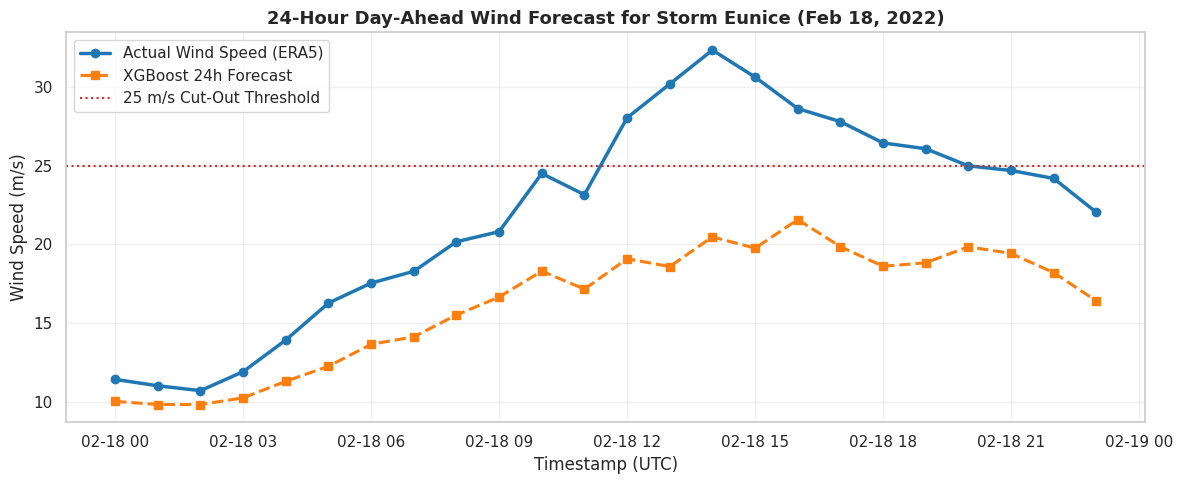

In [20]:
# ---------------------------------------------------------
# 1. Select February 17, 2022 (Input Day) & February 18, 2022 (Target Day)
# ---------------------------------------------------------
input_date_str = "2022-02-17"
target_date_str = "2022-02-18"

# Locate the row representing the final hour of Feb 17 (23:00 UTC)
# This row contains the full 24-hour historical lags and rolling stats from Feb 17
feb17_23h_row = df_clean[
    df_clean["timestamp"] == pd.Timestamp(f"{input_date_str} 23:00:00")
]

if feb17_23h_row.empty:
    raise ValueError(f"Timestamp {input_date_str} 23:00:00 not found in dataset.")

# Extract the input feature vector X (shape: 1 x num_features)
X_feb17 = feb17_23h_row[feature_cols]

# ---------------------------------------------------------
# 2. Run the Model to Forecast Next-Day 24-Hour Wind Speeds
# ---------------------------------------------------------
# `multi_model` outputs an array of shape (1, 24) for hours t+1 to t+24
pred_24h_feb18 = multi_model.predict(X_feb17)

# ---------------------------------------------------------
# 3. Extract Actual Values for Feb 18 for Direct Comparison
# ---------------------------------------------------------
feb18_actual_df = df_clean[
    df_clean["timestamp"].dt.strftime("%Y-%m-%d") == target_date_str
].copy().reset_index(drop=True)

# Combine Actuals and Predictions into a single DataFrame
forecast_feb18_df = pd.DataFrame({
    "timestamp": feb18_actual_df["timestamp"],
    "actual_wind_speed_ms": feb18_actual_df["wind_speed"],
    "predicted_wind_speed_ms": pred_24h_feb18[0]  # <-- Flattened to 1D array here
})

print("=== 24-Hour Forecast vs Actuals for February 18, 2022 ===")
print(forecast_feb18_df.to_string(index=False))

# ---------------------------------------------------------
# 4. Plot February 18, 2022 Hourly Forecast vs Actuals
# ---------------------------------------------------------
plt.figure(figsize=(12, 5))
plt.plot(forecast_feb18_df["timestamp"], forecast_feb18_df["actual_wind_speed_ms"],
         label="Actual Wind Speed (ERA5)", color="#1f77b4", linewidth=2.5, marker="o")
plt.plot(forecast_feb18_df["timestamp"], forecast_feb18_df["predicted_wind_speed_ms"],
         label="XGBoost 24h Forecast", color="#ff7f0e", linewidth=2.2, linestyle="--", marker="s")

plt.axhline(25.0, color="#d62728", linestyle=":", label="25 m/s Cut-Out Threshold")

plt.title("24-Hour Day-Ahead Wind Forecast for Storm Eunice (Feb 18, 2022)", fontsize=13, fontweight="bold")
plt.xlabel("Timestamp (UTC)")
plt.ylabel("Wind Speed (m/s)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor

# 1. Calculate 100m Wind Speed from ERA5 vectors
df["wind_speed"] = np.sqrt(df["u100"]**2 + df["v100"]**2)
df = df.sort_values("timestamp").reset_index(drop=True)

# 2. Create 24 Target Steps for Next Day (t+1 to t+24)
target_cols = [f"target_h{h}" for h in range(1, 25)]
for h in range(1, 25):
    df[f"target_h{h}"] = df["wind_speed"].shift(-h)

# 3. Construct 7-Day Input Features (168 Hours of History)
# Key Hourly Lags across the past 7 days (168 hours)
lags = [0, 1, 2, 3, 6, 12, 24, 48, 72, 96, 120, 144, 168]
for lag in lags:
    df[f"lag_{lag}"] = df["wind_speed"].shift(lag)

# Multi-Scale Rolling Statistics (1-day, 3-day, 7-day windows)
df["rolling_mean_24h"]  = df["wind_speed"].shift(1).rolling(24).mean()
df["rolling_std_24h"]   = df["wind_speed"].shift(1).rolling(24).std()
df["rolling_mean_72h"]  = df["wind_speed"].shift(1).rolling(72).mean()
df["rolling_std_72h"]   = df["wind_speed"].shift(1).rolling(72).std()
df["rolling_mean_168h"] = df["wind_speed"].shift(1).rolling(168).mean()
df["rolling_std_168h"]  = df["wind_speed"].shift(1).rolling(168).std()
df["rolling_max_168h"]  = df["wind_speed"].shift(1).rolling(168).max()

# Multi-day Trend Features (Ramp rates over 1, 3, and 7 days)
df["trend_1d"] = df["lag_0"] - df["lag_24"]
df["trend_3d"] = df["lag_0"] - df["lag_72"]
df["trend_7d"] = df["lag_0"] - df["lag_168"]

# Cyclical Time Encoding
df["hour"] = df["timestamp"].dt.hour
df["day_of_year"] = df["timestamp"].dt.dayofyear
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["day_sin"]  = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_cos"]  = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

feature_cols = (
    [f"lag_{l}" for l in lags] +
    ["rolling_mean_24h", "rolling_std_24h",
     "rolling_mean_72h", "rolling_std_72h",
     "rolling_mean_168h", "rolling_std_168h", "rolling_max_168h",
     "trend_1d", "trend_3d", "trend_7d",
     "hour_sin", "hour_cos", "day_sin", "day_cos"]
)

# Clean NaN rows (requires at least 168 hours of past data)
df_clean = df.dropna().reset_index(drop=True)

# 4. Train Multi-Output Model
train = df_clean[df_clean["timestamp"] < "2023-01-01"]
X_train, y_train = train[feature_cols], train[target_cols]

model_7d = MultiOutputRegressor(XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.03, random_state=42, n_jobs=-1
))
model_7d.fit(X_train, y_train)

# 5. Predict February 18, 2022 using the prior 7 days (Feb 11 - Feb 17)
# Feature vector taken at end of Feb 17 (23:00 UTC)
feb17_end = df_clean[df_clean["timestamp"] == pd.Timestamp("2022-02-17 23:00:00")]
X_feb17_7d = feb17_end[feature_cols]

# Predict 24 hours of Feb 18 (flatten array to 1D to match DataFrame columns)
pred_feb18_7d = model_7d.predict(X_feb17_7d).flatten()

# Extract Feb 18 Actuals for comparison
feb18_actuals = df_clean[
    df_clean["timestamp"].dt.strftime("%Y-%m-%d") == "2022-02-18"
].reset_index(drop=True)

results_df = pd.DataFrame({
    "timestamp": feb18_actuals["timestamp"],
    "actual_wind_speed": feb18_actuals["wind_speed"],
    "predicted_7d_model": pred_feb18_7d
})

print(results_df.head())

            timestamp  actual_wind_speed  predicted_7d_model
0 2022-02-18 00:00:00          11.415592           10.169047
1 2022-02-18 01:00:00          11.009455            9.995919
2 2022-02-18 02:00:00          10.699005           10.249927
3 2022-02-18 03:00:00          11.907766           11.384850
4 2022-02-18 04:00:00          13.923205           12.396769


=== 24-Hour Day-Ahead Wind Speed Forecast for February 18, 2022 ===
Input Window Used: 2022-02-11 00:00:00 to 2022-02-17 23:00:00 (168 Hours)
          timestamp  actual_wind_speed_ms  predicted_wind_speed_7d_model_ms
2022-02-18 00:00:00             11.415592                         10.169047
2022-02-18 01:00:00             11.009455                          9.995919
2022-02-18 02:00:00             10.699005                         10.249927
2022-02-18 03:00:00             11.907766                         11.384850
2022-02-18 04:00:00             13.923205                         12.396769
2022-02-18 05:00:00             16.271988                         13.752493
2022-02-18 06:00:00             17.542803                         15.308728
2022-02-18 07:00:00             18.292593                         16.944181
2022-02-18 08:00:00             20.171469                         17.398899
2022-02-18 09:00:00             20.814075                         17.809404
2022-02-18 10:00:00   

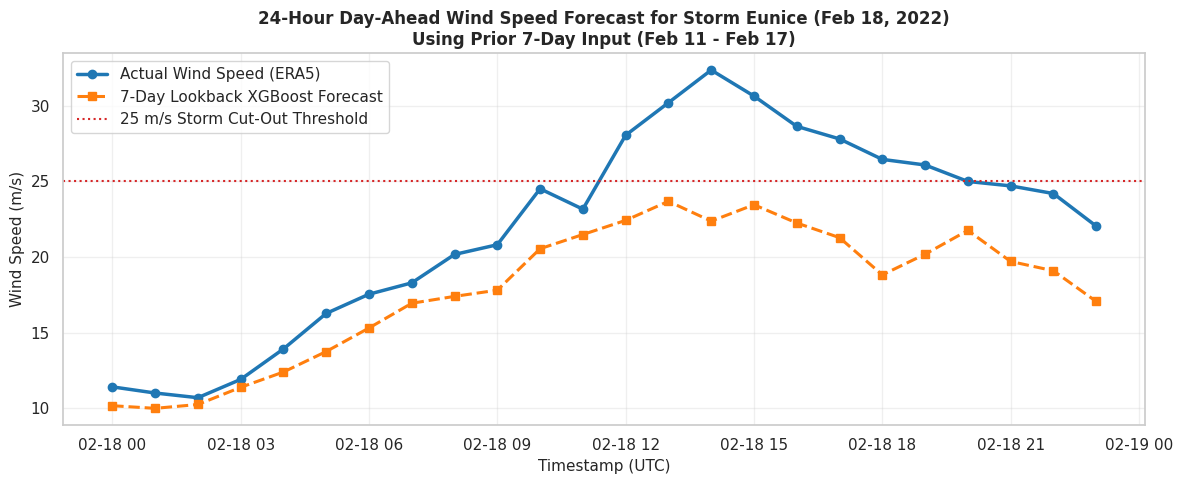

In [22]:
feb17_23h = df_clean[df_clean["timestamp"] == pd.Timestamp("2022-02-17 23:00:00")]

if feb17_23h.empty:
    raise ValueError("Timestamp 2022-02-17 23:00:00 not found in dataset.")

X_feb17_input = feb17_23h[feature_cols]

# Predict next day 24-hour wind speeds (flatten 2D (1,24) array into 1D (24,))
pred_24h_feb18 = model_7d.predict(X_feb17_input).flatten()

# Get actual values for Feb 18, 2022 to construct final table
feb18_actuals = df_clean[
    df_clean["timestamp"].dt.strftime("%Y-%m-%d") == "2022-02-18"
].copy().reset_index(drop=True)

# 24-hour Day-Ahead Forecast DataFrame
forecast_feb18_df = pd.DataFrame({
    "timestamp": feb18_actuals["timestamp"],
    "actual_wind_speed_ms": feb18_actuals["wind_speed"],
    "predicted_wind_speed_7d_model_ms": pred_24h_feb18
})

print("=== 24-Hour Day-Ahead Wind Speed Forecast for February 18, 2022 ===")
print("Input Window Used: 2022-02-11 00:00:00 to 2022-02-17 23:00:00 (168 Hours)")
print(forecast_feb18_df.to_string(index=False))

# ==============================================================================
# 4. PLOT FEB 18, 2022 FORECAST VS ACTUALS
# ==============================================================================
plt.figure(figsize=(12, 5))
plt.plot(forecast_feb18_df["timestamp"], forecast_feb18_df["actual_wind_speed_ms"],
         label="Actual Wind Speed (ERA5)", color="#1f77b4", linewidth=2.5, marker="o")
plt.plot(forecast_feb18_df["timestamp"], forecast_feb18_df["predicted_wind_speed_7d_model_ms"],
         label="7-Day Lookback XGBoost Forecast", color="#ff7f0e", linewidth=2.2, linestyle="--", marker="s")

plt.axhline(25.0, color="#d62728", linestyle=":", label="25 m/s Storm Cut-Out Threshold")

plt.title("24-Hour Day-Ahead Wind Speed Forecast for Storm Eunice (Feb 18, 2022)\nUsing Prior 7-Day Input (Feb 11 - Feb 17)", fontsize=12, fontweight="bold")
plt.xlabel("Timestamp (UTC)", fontsize=11)
plt.ylabel("Wind Speed (m/s)", fontsize=11)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
df["hour"] = df["timestamp"].dt.hour
df["day_of_year"] = df["timestamp"].dt.dayofyear

# Cyclical time features
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["day_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

In [ ]:
# Previous wind speeds
for lag in [1, 3, 6, 12, 24, 48]:
    df[f"lag_{lag}"] = df["wind_speed"].shift(lag)

# Rolling averages using past observations
df["rolling_mean_6h"] = df["wind_speed"].shift(1).rolling(6).mean()
df["rolling_mean_24h"] = df["wind_speed"].shift(1).rolling(24).mean()

# Target: wind speed 24 hours into the future
df["target"] = df["wind_speed"].shift(-24)

df = df.dropna().reset_index(drop=True)

print(df.shape)
print(df.head())

(87600, 19)
            timestamp       u100      v100  wind_speed  hour  day_of_year  \
0 2015-01-03 00:00:00  11.392029  0.164978   11.393224     0            3   
1 2015-01-03 01:00:00  10.223633  1.064117   10.278863     1            3   
2 2015-01-03 02:00:00   9.624847  3.055481   10.098200     2            3   
3 2015-01-03 03:00:00   9.240265  4.619720   10.330746     3            3   
4 2015-01-03 04:00:00   9.716461  4.953217   10.906144     4            3   

   hour_sin  hour_cos   day_sin   day_cos      lag_1      lag_3      lag_6  \
0  0.000000  1.000000  0.051584  0.998669  11.383876  12.699161  13.648205   
1  0.258819  0.965926  0.051584  0.998669  11.393224  11.834475  13.432213   
2  0.500000  0.866025  0.051584  0.998669  10.278863  11.383876  13.360646   
3  0.707107  0.707107  0.051584  0.998669  10.098200  11.393224  12.699161   
4  0.866025  0.500000  0.051584  0.998669  10.330746  10.278863  11.834475   

      lag_12     lag_24     lag_48  rolling_mean_6h  rol

In [ ]:
print("Current wind speed:")
print(df["wind_speed"].head())

print("\nWind speed 24 hours later:")
print(df["target"].head())

Current wind speed:
0    11.393224
1    10.278863
2    10.098200
3    10.330746
4    10.906144
Name: wind_speed, dtype: float32

Wind speed 24 hours later:
0    9.673458
1    9.494493
2    9.253179
3    9.193764
4    8.581045
Name: target, dtype: float32


In [ ]:
# Training and validation/test boundaries
train = df[df["timestamp"] < "2022-01-01"]

validation = df[
    (df["timestamp"] >= "2022-01-01") &
    (df["timestamp"] < "2023-01-01")
]

test = df[df["timestamp"] >= "2023-01-01"]

print("Training:", train.shape)
print("Validation:", validation.shape)
print("Testing:", test.shape)

Training: (61320, 19)
Validation: (8760, 19)
Testing: (17520, 19)


In [ ]:
features = [
    "u100",
    "v100",
    "wind_speed",
    "lag_1",
    "lag_3",
    "lag_6",
    "lag_12",
    "lag_24",
    "lag_48",
    "rolling_mean_6h",
    "rolling_mean_24h",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

X_train = train[features]
y_train = train["target"]

X_val = validation[features]
y_val = validation["target"]

X_test = test[features]
y_test = test["target"]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (61320, 15)
X_val: (8760, 15)
X_test: (17520, 15)


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_predictions = X_test["wind_speed"]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print("Persistence MAE:", baseline_mae)
print("Persistence RMSE:", baseline_rmse)

Persistence MAE: 3.8730857372283936
Persistence RMSE: 4.935713046272695


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Training completed!")

Training completed!


In [ ]:
predictions = model.predict(X_test)

model_mae = mean_absolute_error(y_test, predictions)
model_rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("XGBoost MAE:", model_mae)
print("XGBoost RMSE:", model_rmse)

print("\nPersistence MAE:", baseline_mae)
print("Persistence RMSE:", baseline_rmse)

XGBoost MAE: 3.2088658809661865
XGBoost RMSE: 4.019777043930441

Persistence MAE: 3.8730857372283936
Persistence RMSE: 4.935713046272695


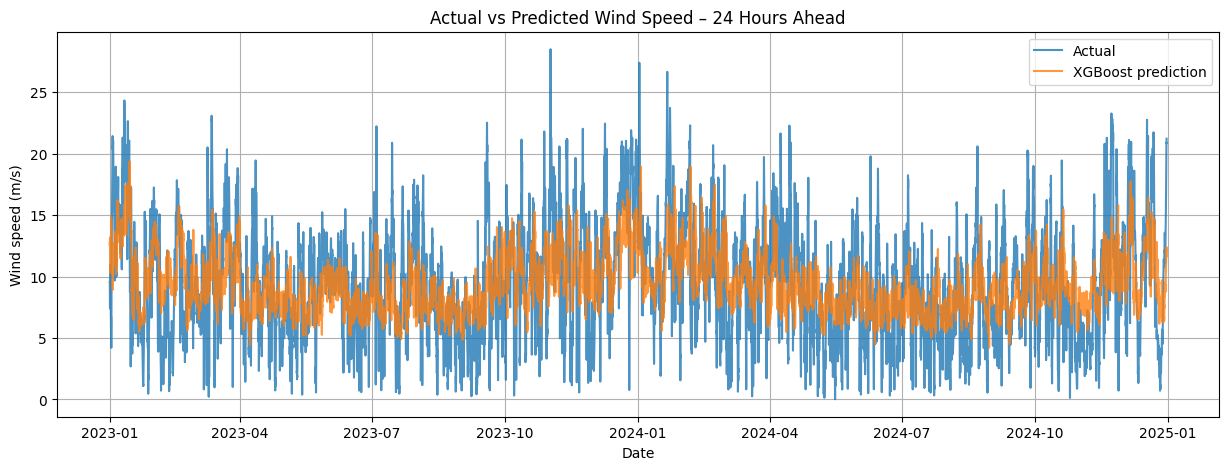

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    test["timestamp"],
    y_test,
    label="Actual",
    alpha=0.8
)

plt.plot(
    test["timestamp"],
    predictions,
    label="XGBoost prediction",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Wind speed (m/s)")
plt.title("Actual vs Predicted Wind Speed – 24 Hours Ahead")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
threshold = 20.0

actual_high_wind = y_test >= threshold
predicted_high_wind = predictions >= threshold

from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(actual_high_wind, predicted_high_wind))

print(
    classification_report(
        actual_high_wind,
        predicted_high_wind,
        zero_division=0
    )
)

[[17211     0]
 [  309     0]]
              precision    recall  f1-score   support

       False       0.98      1.00      0.99     17211
        True       0.00      0.00      0.00       309

    accuracy                           0.98     17520
   macro avg       0.49      0.50      0.50     17520
weighted avg       0.97      0.98      0.97     17520



In [ ]:
plt.figure(figsize=(15, 5))

plt.scatter(
    results["actual"],
    results["predicted"],
    alpha=0.25
)

plt.axvline(20, linestyle="--", label="Actual threshold")
plt.axhline(20, linestyle="--", label="Prediction threshold")

plt.xlabel("Actual wind speed (m/s)")
plt.ylabel("Predicted wind speed (m/s)")
plt.title("Actual vs Predicted Wind Speed")
plt.legend()
plt.grid(True)
plt.show()